# U-Net Arquitectura Básica

Vamos a constuir una arquitecutra U-Net básica (con y sin dropout) para realizar segmentación semántica del dataset Data Science Bowl (2018) que contiene imágenes de tejido biológico dónde se han obtenido mascaras de los nucleos celulares. Usaremos U-net para realizar la segmentación semántica, contruiremos un modelo básico, y luego una modificación con Dropout. El tamaño de las imágenes de entrada será 128x128.

[Enlace Dataset](https://www.kaggle.com/c/data-science-bowl-2018/data)

[Paper Original](https://arxiv.org/pdf/1505.04597.pdf)

## 1. Importamos librerías

In [1]:
import os
import numpy as np
from tqdm import tqdm 
from skimage.io import imread, imshow
from skimage.transform import resize
import matplotlib.pyplot as plt
import datetime

# Librerias para constuir la arquitectura U-Net
from tensorflow.keras.layers import Input, Lambda, Conv2D, Dropout, MaxPooling2D, Conv2DTranspose, concatenate
from tensorflow.keras.models import Model

## 2. Definimos configuración básica

In [4]:
width_shape, height_shape = 128, 128 # Tamaño de las imagenes de entrada
batch_size = 16 
epochs = 5
data_path_train = "stage1_train/"    # Directorio de las imágenes y mascaras de entrenamiento
data_path_test = "stage1_test/"      # Directorio de las imágenes de pruebas

## 3. Adecuamos el dataset

In [5]:
# obtenemos una lista con los archivos dentro de cada carpeta
data_list_train = os.listdir(data_path_train)
data_list_test = os.listdir(data_path_test)

# Definimos listas para guardar cada elemento del dataset
Xtrain=[] 
Ytrain=[]
Xtest=[]

# Recorremos la carpeta train
for folder in tqdm(data_list_train):
    # leemos cada imagen del dataset de entrenamiento y la redimensionamos
    img = imread(data_path_train +folder+ '/images/'  + folder+'.png')[:,:,:3]  
    img = resize(img, (height_shape, width_shape),mode='constant', preserve_range=True)
    # Agregamos cada imagen a la lista Xtrain
    Xtrain.append(img)
    
    # Creamos una mascarar de zeros 
    mask = np.zeros((height_shape, width_shape, 1), dtype=np.bool)
    # Guardamos en una lista todos los archivos en el directorio masks de entrenamiento
    data_list_mask = os.listdir(data_path_train+folder+'/masks/')
    # Recorremos todos los archivos dentro del directorio de masks
    for name_file in data_list_mask:
        # Leemos cada una de las mascaras binarias y las redimensionamos
        maskt = imread(data_path_train +folder+ '/masks/'  + name_file) 
        maskt = resize(maskt, (height_shape, width_shape),mode='constant', preserve_range=True)
        maskt = np.expand_dims(maskt, axis=-1)
        # Unimos la mascara actual con la anterior (equivalente a una operación OR)
        mask = np.maximum(mask, maskt) 
    
    # Agregamos cada mascara a la lista Ytrain
    Ytrain.append(mask)

# Recorremos la carpeta test
for folder in tqdm(data_list_test):
    # leemos cada imagen del dataset de prueba y la redimensionamos
    img = imread(data_path_test +folder+ '/images/'  + folder+'.png')[:,:,:3]  
    img = resize(img, (height_shape, width_shape),mode='constant', preserve_range=True)
    # Agregamos cada imagen a la lista Xtest
    Xtest.append(img)
    
X_train = np.asarray(Xtrain,dtype=np.uint8)
print('Xtrain:',X_train.shape)

Y_train = np.asarray(Ytrain,dtype=np.bool)
print('Ytrain:',Y_train.shape)

X_test = np.asarray(Xtest,dtype=np.uint8)
print('Xtest:',X_test.shape)

  0%|          | 0/670 [00:00<?, ?it/s]

100%|██████████| 65/65 [00:02<00:00, 27.09it/s]


Xtrain: (670, 128, 128, 3)
Ytrain: (670, 128, 128, 1)
Xtest: (65, 128, 128, 3)


## 4. Mostramos algún elemento del dataset

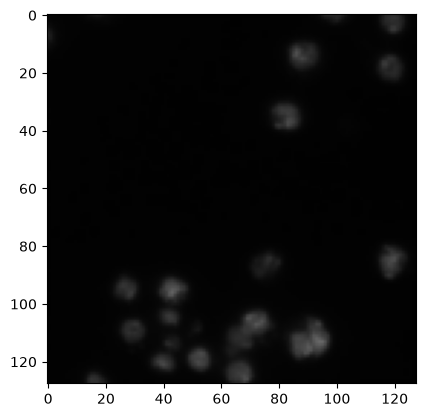

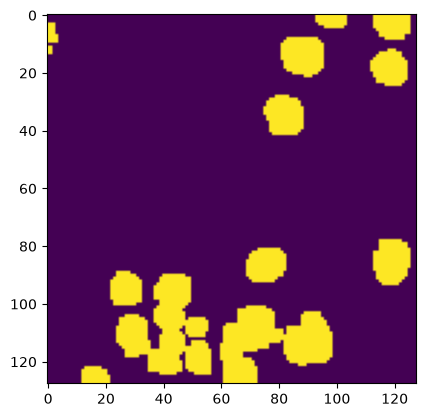

In [6]:
# Mostramos la imagen y su mascara asociada
plt.imshow(X_train[0])
plt.show()
plt.imshow(np.squeeze(Y_train[0]))
plt.show()

## 5. Creamos un modelo básico de U-Net

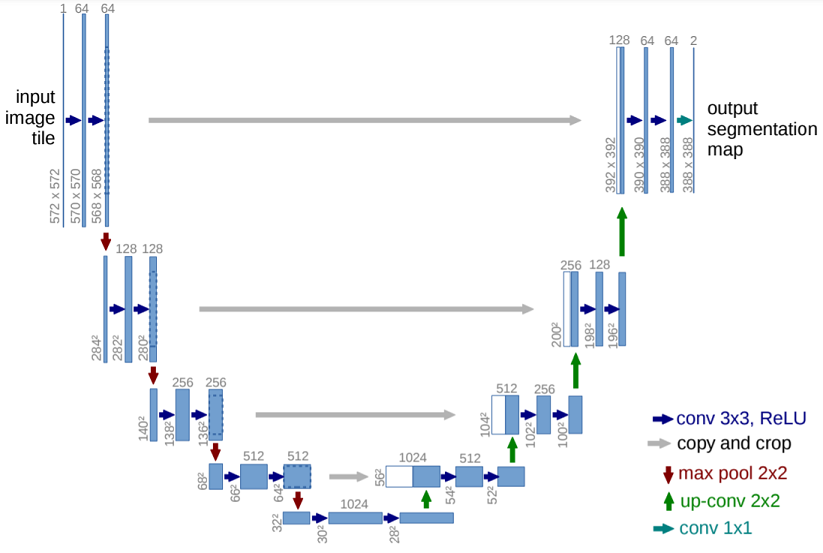

In [7]:
# Definimos la entrada al modelo
Image_input = Input((height_shape, width_shape, 3))
Image_in = Lambda(lambda x: x / 255)(Image_input)

#contracting path
conv1 = Conv2D(64, (3, 3), activation='relu', padding='same')(Image_in)
conv1 = Conv2D(64, (3, 3), activation='relu', padding='same')(conv1)
maxp1 = MaxPooling2D((2, 2))(conv1)

conv2 = Conv2D(128, (3, 3), activation='relu', padding='same')(maxp1)
conv2 = Conv2D(128, (3, 3), activation='relu', padding='same')(conv2)
maxp2 = MaxPooling2D((2, 2))(conv2)
 
conv3 = Conv2D(256, (3, 3), activation='relu', padding='same')(maxp2)
conv3 = Conv2D(256, (3, 3), activation='relu', padding='same')(conv3)
maxp3 = MaxPooling2D((2, 2))(conv3)
 
conv4 = Conv2D(512, (3, 3), activation='relu', padding='same')(maxp3)
conv4 = Conv2D(512, (3, 3), activation='relu', padding='same')(conv4)
maxp4 = MaxPooling2D(pool_size=(2, 2))(conv4)
 
conv5 = Conv2D(1024, (3, 3), activation='relu', padding='same')(maxp4)
conv5 = Conv2D(1024, (3, 3), activation='relu', padding='same')(conv5)

#expansive path
up6 = Conv2DTranspose(512, (2, 2), strides=(2, 2), padding='same')(conv5)
up6 = concatenate([up6, conv4])
conv6 = Conv2D(512, (3, 3), activation='relu', padding='same')(up6)
conv6 = Conv2D(512, (3, 3), activation='relu', padding='same')(conv6)
 
up7 = Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(conv6)
up7 = concatenate([up7, conv3])
conv7 = Conv2D(256, (3, 3), activation='relu', padding='same')(up7)
conv7 = Conv2D(256, (3, 3), activation='relu', padding='same')(conv7)
 
up8 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(conv7)
up8 = concatenate([up8, conv2])
conv8 = Conv2D(128, (3, 3), activation='relu', padding='same')(up8)
conv8 = Conv2D(128, (3, 3), activation='relu', padding='same')(conv8)
 
up9 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(conv8)
up9 = concatenate([up9, conv1], axis=3)
conv9 = Conv2D(64, (3, 3), activation='relu', padding='same')(up9)
conv9 = Conv2D(64, (3, 3), activation='relu', padding='same')(conv9)
 
outputs = Conv2D(1, (1, 1), activation='sigmoid')(conv9)
 
model = Model(inputs=[Image_input], outputs=[outputs])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 128, 128,  │          0 │ input_layer[0][0] │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      1,792 │ lambda[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │     36,928 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    590,080 │ conv2d_4[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_2[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │  2,359,808 │ conv2d_6[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 8, 8, 512) │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 8, 8,      │  4,719,616 │ max_pooling2d_3[… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 8, 8,      │  9,438,208 │ conv2d_8[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │  2,097,664 │ conv2d_9[0][0]  

 Total params: 31,031,745 (118.38 MB)

 Trainable params: 31,031,745 (118.38 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Creamos un modelo U-Net con Dropout

In [ ]:
# Definimos la entrada al modelo

inputs = Lambda(lambda x: x / 255)(Input((height_shape, width_shape, 3)))

#contracting path
conv1 = Conv2D(64, (3, 3), activation='relu', padding='same')(inputs)
conv1 = Dropout(0.1)(conv1)
conv1 = Conv2D(64, (3, 3), activation='relu', padding='same')(conv1)
maxp1 = MaxPooling2D((2, 2))(conv1)

conv2 = Conv2D(128, (3, 3), activation='relu', padding='same')(maxp1)
conv2 = Dropout(0.1)(conv2)
conv2 = Conv2D(128, (3, 3), activation='relu', padding='same')(conv2)
maxp2 = MaxPooling2D((2, 2))(conv2)
 
conv3 = Conv2D(256, (3, 3), activation='relu', padding='same')(maxp2)
conv3 = Dropout(0.2)(conv3)
conv3 = Conv2D(256, (3, 3), activation='relu', padding='same')(conv3)
maxp3 = MaxPooling2D((2, 2))(conv3)
 
conv4 = Conv2D(512, (3, 3), activation='relu', padding='same')(maxp3)
conv4 = Dropout(0.2)(conv4)
conv4 = Conv2D(512, (3, 3), activation='relu', padding='same')(conv4)
maxp4 = MaxPooling2D(pool_size=(2, 2))(conv4)
 
conv5 = Conv2D(1024, (3, 3), activation='relu', padding='same')(maxp4)
conv5 = Dropout(0.3)(conv5)
conv5 = Conv2D(1024, (3, 3), activation='relu', padding='same')(conv5)

#expansive path
up6 = Conv2DTranspose(512, (2, 2), strides=(2, 2), padding='same')(conv5)
up6 = concatenate([up6, conv4])
conv6 = Conv2D(512, (3, 3), activation='relu', padding='same')(up6)
conv6 = Dropout(0.2)(conv6)
conv6 = Conv2D(512, (3, 3), activation='relu', padding='same')(conv6)
 
up7 = Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(conv6)
up7 = concatenate([up7, conv3])
conv7 = Conv2D(256, (3, 3), activation='relu', padding='same')(up7)
conv7 = Dropout(0.2)(conv7)
conv7 = Conv2D(256, (3, 3), activation='relu', padding='same')(conv7)
 
up8 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(conv7)
up8 = concatenate([up8, conv2])
conv8 = Conv2D(128, (3, 3), activation='relu', padding='same')(up8)
conv8 = Dropout(0.1)(conv8)
conv8 = Conv2D(128, (3, 3), activation='relu', padding='same')(conv8)
 
up9 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(conv8)
up9 = concatenate([up9, conv1], axis=3)
conv9 = Conv2D(64, (3, 3), activation='relu', padding='same')(up9)
conv9 = Dropout(0.1)(conv9)
conv9 = Conv2D(64, (3, 3), activation='relu', padding='same')(conv9)
 
outputs = Conv2D(1, (1, 1), activation='sigmoid')(conv9)
 
model = Model(inputs=[inputs], outputs=[outputs])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

## 7. Configuramos Tensorboard

In [8]:
from tensorflow.keras.callbacks import TensorBoard

# Cargamos la extensión, definimos la carpeta logs para guardar los datos de entrenamiento, y definimos el callback
%load_ext tensorboard
logdir = os.path.join("logs", datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
tensorboard_callback = TensorBoard(logdir, histogram_freq=1)

## 8. Entrenamos el modelo

In [10]:
results = model.fit(X_train, Y_train, validation_split=0.1, batch_size=batch_size, epochs=epochs, callbacks=[tensorboard_callback])

Epoch 1/5


KeyboardInterrupt: 

## 9. Revisamos gráficas de entrenamiento

In [ ]:
%reload_ext tensorboard
%tensorboard --logdir logs --host localhost

## 10. Probamos el modelo con alguna imagen de prueba

In [ ]:
preds = model.predict(X_test)
plt.imshow(np.squeeze(preds[1]))
plt.show()
plt.imshow(X_test[1])
plt.show()